# Aula 02 — Pandas e análise de dados industriais
Indústria & Dados · UNISENAI

Complemento didático ao PDF do Prof. Me Daniel Vieira. As resoluções usam as cópias locais fornecidas pelo usuário. Baixe os quatro CSVs para a mesma pasta deste notebook. No Colab, faça o upload dos CSVs. Execute em ordem.

Dependências: pandas, numpy, matplotlib e scikit-learn. A seção opcional de Spark requer pyspark e Java compatível. Nenhum dado é enviado automaticamente a serviços externos.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
BASE = Path('.')
arquivos = ['producao.csv', 'base_p52.csv', 'base_p54.csv', 'manutencao.csv']
for nome in arquivos:
    if not (BASE/nome).exists():
        raise FileNotFoundError(f'Envie {nome} para a pasta do notebook antes de continuar.')
print('Pandas:', pd.__version__)

Pandas: 3.0.1


## 1. Pandas: estrutura, seleção e indicadores
PDF 8–34. Os cinco registros do exemplo são transcritos abaixo; a unidade da temperatura não foi especificada no exemplo original.

In [2]:
df = pd.DataFrame({'produto': ['Motor A','Motor B','Motor A','Motor C','Motor B'],
 'producao': [100,120,110,90,130], 'defeitos': [5,12,6,3,15], 'temperatura': [70,82,73,68,85]})
print(df)
print(df.loc[df['temperatura'] > 75, ['produto','temperatura']])
print(df.groupby('produto')['producao'].mean())
df['taxa_defeitos_pct'] = 100 * df['defeitos'] / df['producao'].where(df['producao'] > 0)
print(df.describe())
print(df[['temperatura','defeitos','taxa_defeitos_pct']].corr())
assert df['temperatura'].mean() == 75.6

   produto  producao  defeitos  temperatura
0  Motor A       100         5           70
1  Motor B       120        12           82
2  Motor A       110         6           73
3  Motor C        90         3           68
4  Motor B       130        15           85
   produto  temperatura
1  Motor B           82
4  Motor B           85
produto
Motor A    105.0
Motor B    125.0
Motor C     90.0
Name: producao, dtype: float64
         producao   defeitos  temperatura  taxa_defeitos_pct
count    5.000000   5.000000     5.000000           5.000000
mean   110.000000   8.200000    75.600000           7.065268
std     15.811388   5.069517     7.503333           3.514584
min     90.000000   3.000000    68.000000           3.333333
25%    100.000000   5.000000    70.000000           5.000000
50%    110.000000   6.000000    73.000000           5.454545
75%    120.000000  12.000000    82.000000          10.000000
max    130.000000  15.000000    85.000000          11.538462
                   temper

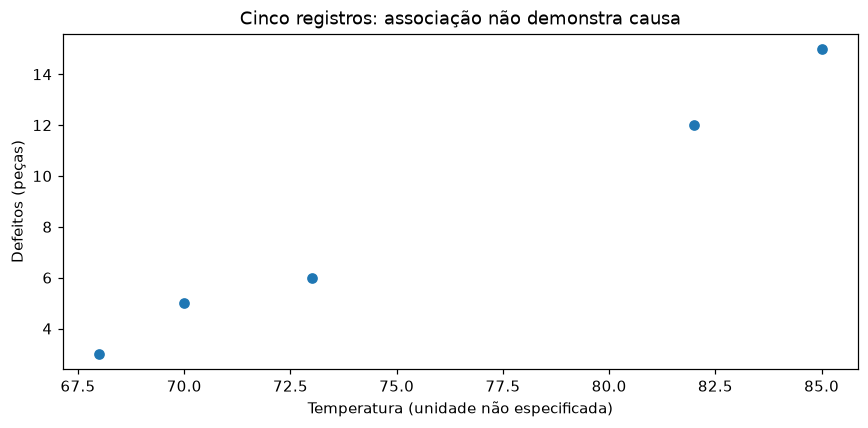

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(df['temperatura'], df['defeitos'])
ax.set(xlabel='Temperatura (unidade não especificada)', ylabel='Defeitos (peças)', title='Cinco registros: associação não demonstra causa')
fig.tight_layout()
plt.show()

## 2. Produção e qualidade por turno
PDF 35–48 e 51. Responda ao total, maior turno, médias, taxas e associação produção/defeitos. A taxa usa totais agregados, não a média simples das porcentagens.

In [4]:
producao = pd.read_csv(BASE/'producao.csv', parse_dates=['data'])
assert producao.shape == (100, 6)
assert (producao['pecas_aprovadas'] + producao['pecas_defeituosas']).equals(producao['pecas_produzidas'])
resumo = producao.groupby('turno').agg(registros=('pecas_produzidas','size'),
 produzidas=('pecas_produzidas','sum'), defeituosas=('pecas_defeituosas','sum'), media=('pecas_produzidas','mean'))
resumo['taxa_pct'] = 100 * resumo['defeituosas'] / resumo['produzidas']
print('Total:', producao['pecas_produzidas'].sum())
print(resumo.round(4))
print('Maior produção:', resumo['produzidas'].idxmax())
print('Maior taxa:', resumo['taxa_pct'].idxmax())
print('Correlação:', producao['pecas_produzidas'].corr(producao['pecas_defeituosas']))
assert producao['pecas_produzidas'].sum() == 29479

Total: 29479
       registros  produzidas  defeituosas     media  taxa_pct
turno                                                        
Manhã         34       10777          358  316.9706    3.3219
Noite         33        8765          277  265.6061    3.1603
Tarde         33        9937          306  301.1212    3.0794
Maior produção: Manhã
Maior taxa: Manhã
Correlação: 0.3696564216740088


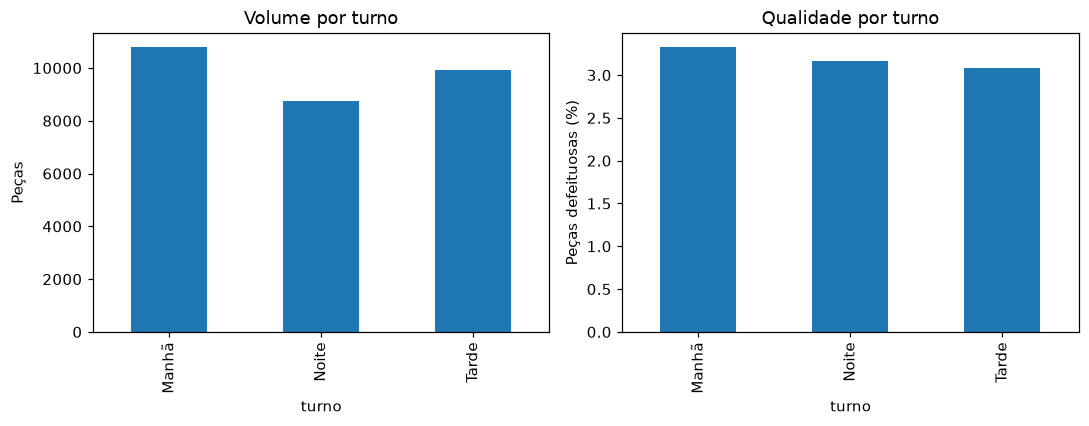

In [5]:
fig, axes = plt.subplots(1,2,figsize=(10,4))
resumo['produzidas'].plot.bar(ax=axes[0], title='Volume por turno', ylabel='Peças')
resumo['taxa_pct'].plot.bar(ax=axes[1], title='Qualidade por turno', ylabel='Peças defeituosas (%)')
fig.tight_layout()
plt.show()

## 3. Exercício 1 — máquinas e energia
PDF 49–50. A tabela foi conferida visualmente com o slide 49.

In [6]:
maquinas = pd.DataFrame({'maquina': list('ABCDE'), 'producao': [1250,1380,1190,1450,1320],
 'energia_kwh': [420,465,390,510,405]})
maquinas['eficiencia'] = maquinas['producao'] / maquinas['energia_kwh']
print('a) Maior produção:', maquinas.loc[maquinas['producao'].idxmax(), 'maquina'])
print('b) Menor consumo:', maquinas.loc[maquinas['energia_kwh'].idxmin(), 'maquina'])
print('c) Produção média:', maquinas['producao'].mean())
print('d) Energia média:', maquinas['energia_kwh'].mean())
print('e) Ranking de produção:', maquinas.sort_values('producao', ascending=False)['maquina'].tolist())
print('f) Eficiência (peças/kWh):\n', maquinas)
print('g) Melhor eficiência:', maquinas.loc[maquinas['eficiencia'].idxmax(), 'maquina'])
assert maquinas.loc[maquinas['eficiencia'].idxmax(), 'maquina'] == 'E'

a) Maior produção: D
b) Menor consumo: C
c) Produção média: 1318.0
d) Energia média: 438.0
e) Ranking de produção: ['D', 'B', 'E', 'A', 'C']
f) Eficiência (peças/kWh):
   maquina  producao  energia_kwh  eficiencia
0       A      1250          420    2.976190
1       B      1380          465    2.967742
2       C      1190          390    3.051282
3       D      1450          510    2.843137
4       E      1320          405    3.259259
g) Melhor eficiência: E


## 4. Exercício 2 — viagens
PDF 52–53. Confira uma linha por data e a cobertura dos meses antes de interpretar totais mensais.

Nota sobre o PDF: as imagens das tabelas dos slides 52 e 54 estão trocadas em relação aos enunciados. Neste notebook, os exercícios são associados às colunas corretas das bases locais: viagens/distância e preço/unidades/faturamento.

In [7]:
viagens = pd.read_csv(BASE/'base_p52.csv', parse_dates=['data'])
assert not viagens['data'].duplicated().any()
print('a) Total:', viagens['quantidade_viagens'].sum())
print('b) Maior dia:', viagens.loc[viagens['quantidade_viagens'].idxmax(), ['data','quantidade_viagens']])
print('c) Média diária observada:', viagens['quantidade_viagens'].mean())
mensal = viagens.groupby(viagens['data'].dt.to_period('M')).agg(dias=('data','size'), viagens=('quantidade_viagens','sum'))
print('d) Totais e cobertura mensal:\n', mensal)
print('Maior mês:', mensal['viagens'].idxmax())
print('e) Correlação viagens/distância:', viagens['quantidade_viagens'].corr(viagens['distancia_total_km']))
assert viagens['quantidade_viagens'].sum() == 2893

a) Total: 2893
b) Maior dia: data                  2026-02-26 00:00:00
quantidade_viagens                     48
Name: 56, dtype: object
c) Média diária observada: 28.93
d) Totais e cobertura mensal:
          dias  viagens
data                  
2026-01    31      901
2026-02    28      816
2026-03    31      895
2026-04    10      281
Maior mês: 2026-01
e) Correlação viagens/distância: 0.8693500045093394


## 5. Exercício 3 — vendas
PDF 54–55. Faturamento depende de preço e quantidade; associação temporal não isola causalidade.

In [8]:
vendas = pd.read_csv(BASE/'base_p54.csv')
vendas['mes'] = pd.to_datetime(vendas['mes'], format='%Y-%m')
assert not vendas['mes'].duplicated().any()
assert np.allclose(vendas['unidades_vendidas']*vendas['preco_unitario_rs'], vendas['faturamento_rs'], atol=0.01)
print('a) Total de unidades:', vendas['unidades_vendidas'].sum())
print('b) Maior mês:', vendas.loc[vendas['faturamento_rs'].idxmax(), ['mes','faturamento_rs']])
print('c) Faturamento total:', vendas['faturamento_rs'].sum())
anual = vendas.groupby(vendas['mes'].dt.year).agg(meses=('mes','size'), unidades=('unidades_vendidas','sum'))
print('d) Unidades e cobertura anual:\n', anual)
print('Maior ano:', anual['unidades'].idxmax())
print('e) Correlação preço/quantidade:', vendas['preco_unitario_rs'].corr(vendas['unidades_vendidas']))

a) Total de unidades: 24499
b) Maior mês: mes               2025-11-01 00:00:00
faturamento_rs               22516.32
Name: 94, dtype: object
c) Faturamento total: 1281779.1700000002
d) Unidades e cobertura anual:
       meses  unidades
mes                  
2018     12      2330
2019     12      2363
2020     12      2600
2021     12      2800
2022     12      3102
2023     12      3280
2024     12      3370
2025     12      3511
2026      4      1143
Maior ano: 2025
e) Correlação preço/quantidade: 0.7713452839650177


## Projeto S&M — etapa 1: compreensão e exploração
PDF 57–70. A unidade é o registro de sensor por máquina/instante. O rótulo falha descreve o registro; não representa automaticamente um evento independente ou previsão futura.

In [9]:
bruta = pd.read_csv(BASE/'manutencao.csv')
print('Dimensões brutas:', bruta.shape)
print('Ausentes por coluna:\n', bruta.isna().sum())
print('Duplicatas exatas:', bruta.duplicated().sum())
base = bruta.drop_duplicates().copy()
base['timestamp'] = pd.to_datetime(base['timestamp'], errors='raise')
base = base.sort_values(['timestamp','maquina_id']).reset_index(drop=True)
sensores = ['temperatura_c','vibracao_mm_s','pressao_bar','corrente_a','horas_operacao']
assert set(base['falha'].dropna().unique()).issubset({0,1})
assert base['falha'].notna().all()
print(base[sensores].describe())
perfil = base.groupby('maquina_id')['falha'].agg(['size','sum','mean'])
print('Taxa por máquina:\n', perfil)
print('Percentual global de registros com falha:', 100*base['falha'].mean())
assert bruta.shape == (5050, 8)
assert len(base) == 5000

Dimensões brutas: (5050, 8)
Ausentes por coluna:
 timestamp          0
maquina_id         0
temperatura_c     52
vibracao_mm_s     50
pressao_bar       51
corrente_a        50
horas_operacao    51
falha              0
dtype: int64
Duplicatas exatas: 50
       temperatura_c  vibracao_mm_s  pressao_bar   corrente_a  horas_operacao
count    4950.000000    4950.000000  4950.000000  4950.000000     4950.000000
mean       67.115515       3.057529     6.500927    25.671125     6098.534343
std        12.548481       0.905164     0.649887     2.713360     3439.189145
min        41.330000       0.230000     4.250000    14.810000      102.000000
25%        61.572500       2.520000     6.070000    23.850000     3092.250000
50%        66.515000       3.030000     6.500000    25.680000     6122.000000
75%        71.390000       3.540000     6.940000    27.440000     9016.750000
max       278.840000      15.120000     9.160000    35.330000    11999.000000
Taxa por máquina:
             size  sum   me

## Etapa 2: preparação e mineração
PDF 71–72. Preserve o bruto e registre tratamentos. Não elimine extremos sem justificativa. A imputação destinada ao modelo será ajustada no treino dentro de um pipeline.

       temperatura_c  vibracao_mm_s  pressao_bar  corrente_a  horas_operacao
falha                                                                       
0             65.870           2.91         6.51       25.47          5280.5
1             69.685           3.60         6.48       26.60          9547.5
pressao_bar      -0.021649
temperatura_c     0.111714
corrente_a        0.163049
vibracao_mm_s     0.303858
horas_operacao    0.380739
falha             1.000000
Name: falha, dtype: float64


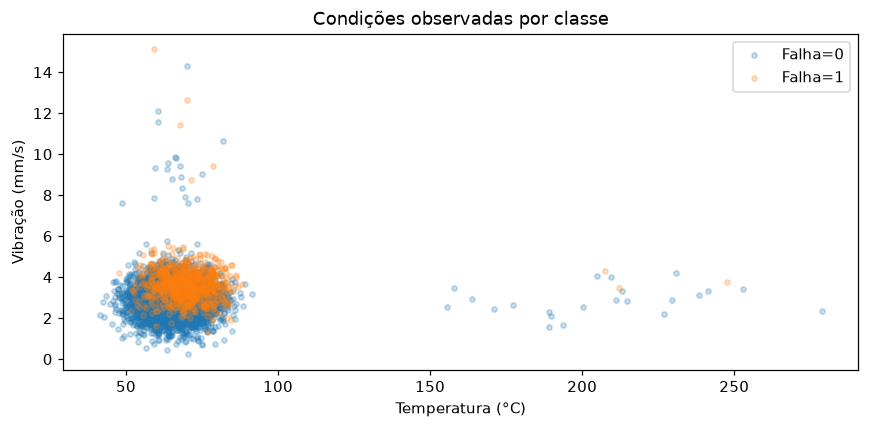

In [10]:
print(base.groupby('falha')[sensores].median())
print(base[sensores + ['falha']].corr()['falha'].sort_values())
fig, ax = plt.subplots(figsize=(8,4))
for classe, grupo in base.groupby('falha'):
    ax.scatter(grupo['temperatura_c'], grupo['vibracao_mm_s'], alpha=.25, s=12, label=f'Falha={classe}')
ax.set(xlabel='Temperatura (°C)', ylabel='Vibração (mm/s)', title='Condições observadas por classe')
ax.legend()
fig.tight_layout()
plt.show()

## Etapa 3: classificação supervisionada
PDF 73–74. O exemplo abaixo usa corte temporal, mantendo o mesmo instante no mesmo conjunto. Compara dois modelos em validação; avalia apenas o escolhido no teste final e uma referência majoritária. Isso não comprova previsão antecipada de paradas. Antes de usar em produção, defina horizonte e disponibilidade de cada sensor.

F1 na validação: {'Arvore': 0.46558704453441296, 'Logistica': 0.5145067698259188}
Modelo escolhido pela validação: Logistica
Teste final:
               precision    recall  f1-score   support

           0       0.93      0.69      0.79       812
           1       0.37      0.78      0.50       188

    accuracy                           0.71      1000
   macro avg       0.65      0.73      0.65      1000
weighted avg       0.83      0.71      0.74      1000

Referência majoritária:
               precision    recall  f1-score   support

           0       0.81      1.00      0.90       812
           1       0.00      0.00      0.00       188

    accuracy                           0.81      1000
   macro avg       0.41      0.50      0.45      1000
weighted avg       0.66      0.81      0.73      1000



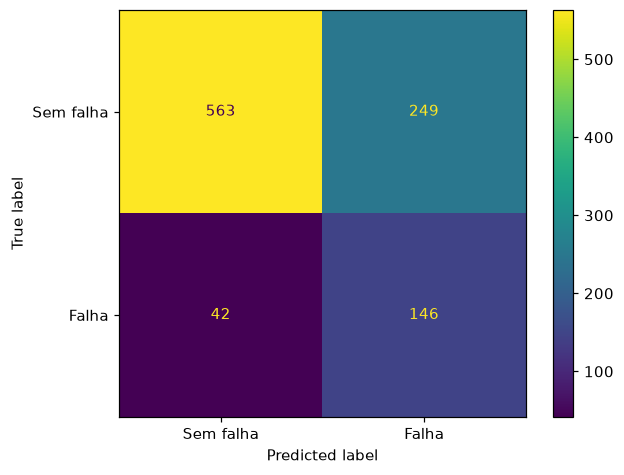

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay
instantes = np.sort(base['timestamp'].unique())
corte_validacao = instantes[int(len(instantes)*.6)]
corte_teste = instantes[int(len(instantes)*.8)]
treino = base['timestamp'] < corte_validacao
validacao = (base['timestamp'] >= corte_validacao) & (base['timestamp'] < corte_teste)
teste = base['timestamp'] >= corte_teste
X, y = base[sensores], base['falha']
modelos = {
 'Arvore': DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
 'Logistica': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42)
}
pipelines = {nome: Pipeline([('imputacao', SimpleImputer(strategy='median')),
 ('escala', StandardScaler()), ('modelo', estimador)]) for nome, estimador in modelos.items()}
validacoes = {}
for nome, pipeline in pipelines.items():
    pipeline.fit(X.loc[treino], y.loc[treino])
    validacoes[nome] = f1_score(y.loc[validacao], pipeline.predict(X.loc[validacao]), zero_division=0)
print('F1 na validação:', validacoes)
escolhido = max(validacoes, key=validacoes.get)
final = pipelines[escolhido].fit(X.loc[treino | validacao], y.loc[treino | validacao])
previsao = final.predict(X.loc[teste])
referencia = DummyClassifier(strategy='most_frequent').fit(X.loc[treino | validacao], y.loc[treino | validacao])
print('Modelo escolhido pela validação:', escolhido)
print('Teste final:\n', classification_report(y.loc[teste], previsao, zero_division=0))
print('Referência majoritária:\n', classification_report(y.loc[teste], referencia.predict(X.loc[teste]), zero_division=0))
ConfusionMatrixDisplay.from_predictions(y.loc[teste], previsao, labels=[0,1], display_labels=['Sem falha','Falha'])
plt.show()

## Etapa 4: perfis com K-Means
PDF 75–76. O rótulo falha não entra no agrupamento. Compare K com inércia, silhueta e interpretação; a escolha por silhueta é uma heurística, não uma verdade operacional.

In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.pipeline import make_pipeline
preparacao = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
Z = preparacao.fit_transform(base[sensores])
candidatos, ajustes = [], {}
for k in range(2, 6):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    ajustes[k] = km
    candidatos.append({'k': k, 'inercia': km.inertia_,
      'silhueta': silhouette_score(Z, km.labels_, sample_size=min(1000,len(Z)), random_state=42)})
comparacao = pd.DataFrame(candidatos)
print(comparacao)
k = int(comparacao.loc[comparacao['silhueta'].idxmax(), 'k'])
perfis = base.assign(cluster=ajustes[k].labels_)
print('K escolhido nesta heurística:', k)
print(perfis.groupby('cluster')[sensores].median())
print(perfis.groupby('cluster')['falha'].agg(['size','mean']))

   k       inercia  silhueta
0  2  19692.287401  0.218090
1  3  16538.396782  0.223303
2  4  14576.080084  0.189825
3  5  13093.241050  0.168217
K escolhido nesta heurística: 3
         temperatura_c  vibracao_mm_s  pressao_bar  corrente_a  horas_operacao
cluster                                                                       
0               65.035           2.58        6.470       24.73          3188.5
1               67.980           3.49        6.540       26.71          8974.0
2              209.610           2.87        6.645       26.38          5839.0
         size      mean
cluster                
0        2509  0.044639
1        2466  0.319546
2          25  0.120000


## Etapa 5: PySpark e recomendações
PDF 77–79. A célula é opcional: instale pyspark e Java compatível, depois altere EXECUTAR_SPARK para True. Ela não instala software automaticamente. A base pequena serve para aprender a API; não demonstra vantagem de desempenho distribuído. Para uma versão ampliada, documente como os dados foram gerados; repetições artificiais não são evidência nova.

In [13]:
EXECUTAR_SPARK = False
if EXECUTAR_SPARK:
    from pyspark.sql import SparkSession, functions as F
    spark = SparkSession.builder.master('local[*]').appName('Aula02').getOrCreate()
    try:
        sdf = spark.read.csv(str(BASE/'manutencao.csv'), header=True, inferSchema=True).dropDuplicates()
        sdf.select('maquina_id','temperatura_c','falha').filter(F.col('falha') == 1).show(5)
        sdf.groupBy('maquina_id').agg(F.count('*').alias('registros'), F.avg('falha').alias('taxa_falha')).show()
    finally:
        spark.stop()
else:
    print('Spark não executado. Instale as dependências e ative a opção para desenvolver esta etapa.')

Spark não executado. Instale as dependências e ative a opção para desenvolver esta etapa.


## Sua interpretação e entrega
Complete com suas próprias conclusões:

1. Quais achados são mais relevantes e que dados os sustentam?
2. Qual modelo foi escolhido, por qual métrica e quais são suas limitações?
3. Como interpretar os perfis de operação?
4. O que o Spark permitiu reproduzir e que escala real justificaria usá-lo?
5. Quais recomendações de monitoramento/manutenção podem ser testadas?

Rubrica do slide 80: exploração 15; tratamento 15; análise/mineração 15; classificação 25; agrupamento 10; Spark 10; interpretação e recomendações 10. Total 100. O campus não envia a atividade.

Fontes técnicas: [Pandas](https://pandas.pydata.org/docs/getting_started/intro_tutorials/), [Scikit-learn](https://scikit-learn.org/stable/common_pitfalls.html), [PySpark](https://spark.apache.org/docs/latest/api/python/getting_started/quickstart_df.html).